# Notebook 01 - Fundamentals: from measurements to cost functions

In [40]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.executor_sampler import Sampler
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import Statevector

\<ZZ\> values determined from count - AerSimulator vs QPU  
Each bit 0 is read as (+1) and 1 is read as (-1)

**Interpretation:** 

-The simulator gives a perfect correlation: 1.0

-On the QPU, 6.9% of the shots gave `01` or `10`, so \<ZZ\> = 1 − 2 x 0.069 = 0.862 (the hardware errors from Notebook-00 show up directly in the expectation value)

Max-Cut Hamiltonians are sums of exactly these ZZ terms, one per edge

In [41]:
count_aer = {"00":479, "11":521}
count_qpu = {"00":475, "01":35, "10":34, "11":456}

In [42]:
def zz_expected(counts, i, j):
    total_shots = sum(counts.values())

    s = 0
    for bitstring, count in counts.items():
        if bitstring[-1-i] == "0":
            zi = 1
        else:
            zi = -1

        if bitstring[-1-j] == "0":
            zj = 1
        else:
            zj = -1

        s += zi * zj * count

    return s / total_shots


print("Aer simulator:", zz_expected(count_aer, 0, 1))
print("IBM QPU:", zz_expected(count_qpu, 0, 1))

Aer simulator: 1.0
IBM QPU: 0.862


In [43]:
sim = AerSimulator()
pm = generate_preset_pass_manager(backend=sim, optimization_level=1)
sampler = Sampler(mode=sim)

for theta in [0, np.pi / 2, np.pi]:
    qc = QuantumCircuit(1)
    qc.h(0)
    qc.rz(theta, 0)
    qc.h(0)
    qc.measure_all()

    isa_qc = pm.run(qc)
    job = sampler.run([isa_qc], shots=1000)
    counts = job.result()[0].data.meas.get_counts()

    zeros = counts.get("0", 0)
    measured = zeros / 1000

    # theory prediction
    predicted = np.cos(theta / 2) ** 2
    
    sigma = np.sqrt(predicted * (1 - predicted) / 1000)

    print(f"theta = {theta:.2f}")
    print(f"measured P(0) = {measured:.3f}")
    print(f"predicted P(0) = {predicted:.3f}")
    print(f"sigma = {sigma:.3f}")
    print()

theta = 0.00
measured P(0) = 1.000
predicted P(0) = 1.000
sigma = 0.000

theta = 1.57
measured P(0) = 0.480
predicted P(0) = 0.500
sigma = 0.016

theta = 3.14
measured P(0) = 0.000
predicted P(0) = 0.000
sigma = 0.000



## **The Hamiltonian of a triangle**

For every edge (i, j) the term 0.5 * (I - ZiZj) is:

-1 if the edge is cut (<=> bits differ)

-0 otherwise

H counts the cut edges

In [44]:
edges = [(0, 1), (0, 2), (1, 2)]

terms = []
for edge in edges:
    i = edge[0]
    j = edge[1]
    terms.append(("I", [0], 0.5))
    terms.append(("ZZ", [i, j], -0.5))

H = SparsePauliOp.from_sparse_list(terms, num_qubits=3).simplify()
print(H)

SparsePauliOp(['III', 'IZZ', 'ZIZ', 'ZZI'],
              coeffs=[ 1.5+0.j, -0.5+0.j, -0.5+0.j, -0.5+0.j])


In [45]:
matrix = H.to_matrix()
print(matrix.shape)

diagonal = matrix.diagonal()
print(diagonal)

(8, 8)
[0.+0.j 2.+0.j 2.+0.j 2.+0.j 2.+0.j 2.+0.j 2.+0.j 0.+0.j]


In [46]:
# show the link between the configuration and the cost
for k in range(8):
    bitstring = format(k, "03b")
    cost = diagonal[k].real
    print(bitstring, "->", cost)

000 -> 0.0
001 -> 2.0
010 -> 2.0
011 -> 2.0
100 -> 2.0
101 -> 2.0
110 -> 2.0
111 -> 0.0


**Interpretation:** The diagonal of H is exactly the number of edges cut by each bitstring:
`000` and `111` put all three processes on one machine (cut 0); every other bitstring cuts 2 edges, the maximum for a triangle

**The diagonal of the Hamiltonian is the cost function** - this is what makes the problem solvable on a quantum computer

Bit i says on which machine process i runs: 0 - on machine A; 1 - on machine B

In [47]:
def bitstring_to_partition(bitstring):
    machine_a = []
    machine_b = []

    reversed_bitstring = bitstring[::-1]
    
    for i in range(len(bitstring)):
        if (reversed_bitstring[i] == "0"):
            machine_a.append(i)
        else:
            machine_b.append(i)
    return machine_a, machine_b

Statevector([0.35355339+0.j, 0.35355339+0.j, 0.35355339+0.j,
             0.35355339+0.j, 0.35355339+0.j, 0.35355339+0.j,
             0.35355339+0.j, 0.35355339+0.j],
            dims=(2, 2, 2))
[0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]


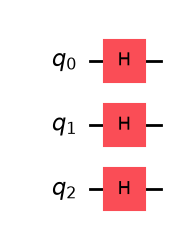

In [48]:
qc = QuantumCircuit(3)

qc.h(0)
qc.h(1)
qc.h(2)

state = Statevector(qc)
print(state)

probabilities = state.probabilities()
print(probabilities)

qc.draw("mpl")

In [49]:
# cost - manual
average_cost = 0
for item in range(8):
    average_cost += probabilities[item] * diagonal[item].real

print("Average cost (manual): ", average_cost)

Average cost (manual):  1.4999999999999996


In [50]:
# cost - with StateVector
estimator = StatevectorEstimator()
job = estimator.run([(qc, H)])
result = job.result()

energy = result[0].data.evs
print("Energy from Estimator:", energy)

Energy from Estimator: 1.4999999999999993
